# EN3160 - Assignment 03: Neural Networks

**Name:** Bandara H.Y.W. 
**Index Number:** 230074J 
**GitHub:** https://github.com/YohanBandara/Computer-Vision

## Introduction

In this assignment I implemented a manually trained dense neural network, two CNN models for MNIST, and transfer learning using ResNet18. The models are trained and evaluated using PyTorch.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models
import matplotlib.pyplot as plt
import os

torch.manual_seed(0)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("MPS available:", torch.backends.mps.is_available())
print("Device:", device)


MPS available: True
Device: mps


# 1. Dense Neural Network with Manual Backpropagation

The given one-layer network is changed by adding a hidden layer with 100 neurons. Sigmoid is used as the hidden layer activation and cross-entropy is used as the loss. The network is trained for 10 epochs on CIFAR-10.

## 1.1 Load CIFAR-10 Dataset

In [7]:
import os

print("Working folder:", os.getcwd())
print("CIFAR-10 already extracted:", os.path.isdir("./data/cifar-10-batches-py"))
print("First download is about 163 MB and may take a few minutes.")

Working folder: /Users/yohanbandara/Documents/vs code/sem 5/CV semester 5/CV assignment3
CIFAR-10 already extracted: False
First download is about 163 MB and may take a few minutes.


In [8]:
import torchvision
import torchvision.transforms as transforms

transform_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform_cifar
)

print("Training images:", len(trainset))

100%|██████████| 170M/170M [1:04:14<00:00, 44.2kB/s] 


Training images: 50000


In [ ]:
transform_cifar = transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform_cifar)

trainloader = torch.utils.data.DataLoader(trainset,batch_size=batch_size,shuffle=True,num_workers=0)

testset = torchvision.datasets.CIFAR10(root="./data",train=False,download=True,transform=transform_cifar)

testloader = torch.utils.data.DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=0)

classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

print("Training images:", len(trainset))
print("Test images:", len(testset))


Training images: 50000
Test images: 10000


## 1.2 Define Network Parameters

The input image is flattened to 3072 values. The hidden layer contains 100 neurons and the output layer contains 10 neurons for the CIFAR-10 classes.

In [10]:
Din = 3 * 32 * 32
H = 100
K = 10

w1 = torch.randn(Din, H, device=device) * 0.01
b1 = torch.zeros(H, device=device)

w2 = torch.randn(H, K, device=device) * 0.01
b2 = torch.zeros(K, device=device)

epochs = 10
lr = 0.1
lr_decay = 0.95

loss_history_q1 = []

## 1.3 Training with Manual Forward Pass and Backpropagation

Softmax probabilities are used to calculate cross-entropy loss. The gradients are calculated manually and the weights are updated using gradient descent.

In [ ]:
for epoch in range(epochs):
    running_loss = 0.0

    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        N = inputs.shape[0]
        x = inputs.view(N, -1)

        # Forward pass
        z1 = x.mm(w1) + b1
        h1 = torch.sigmoid(z1)

        scores = h1.mm(w2) + b2

        # Softmax
        scores = scores - scores.max(dim=1, keepdim=True).values
        exp_scores = torch.exp(scores)
        probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)

        # Cross entropy loss
        loss = -torch.log(
            probs[torch.arange(N, device=device), labels] + 1e-12
        ).mean()

        running_loss += loss.item()

        # Backpropagation
        dscores = probs.clone()
        dscores[torch.arange(N, device=device), labels] -= 1
        dscores /= N

        dw2 = h1.t().mm(dscores)
        db2 = dscores.sum(dim=0)

        dh1 = dscores.mm(w2.t())
        dz1 = dh1 * h1 * (1 - h1)

        dw1 = x.t().mm(dz1)
        db1 = dz1.sum(dim=0)

        # Update parameters
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    epoch_loss = running_loss / len(trainloader)
    loss_history_q1.append(epoch_loss)

    print(f"Epoch {epoch + 1}/10 - Loss: {epoch_loss:.4f}")

    lr *= lr_decay

Epoch 1/10 - Loss: 1.9021
Epoch 2/10 - Loss: 1.7176
Epoch 3/10 - Loss: 1.6481
Epoch 4/10 - Loss: 1.5950
Epoch 5/10 - Loss: 1.5507
Epoch 6/10 - Loss: 1.5108
Epoch 7/10 - Loss: 1.4743
Epoch 8/10 - Loss: 1.4432
Epoch 9/10 - Loss: 1.4128
Epoch 10/10 - Loss: 1.3845


## 1.4 Loss Curve

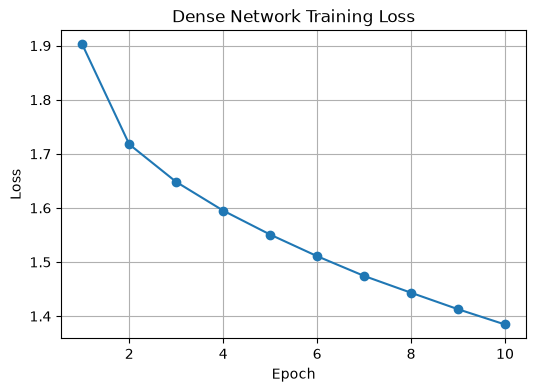

In [12]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), loss_history_q1, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dense Network Training Loss")
plt.grid()
plt.show()

## 1.5 Training and Test Accuracy

In [13]:
def dense_accuracy(loader):
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            x = inputs.view(inputs.shape[0], -1)

            h1 = torch.sigmoid(x.mm(w1) + b1)
            scores = h1.mm(w2) + b2

            predicted = torch.argmax(scores, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return 100 * correct / total


train_acc_q1 = dense_accuracy(trainloader)
test_acc_q1 = dense_accuracy(testloader)

print(f"Training Accuracy: {train_acc_q1:.2f}%")
print(f"Test Accuracy: {test_acc_q1:.2f}%")

Training Accuracy: 53.45%
Test Accuracy: 47.54%


### Result and Discussion

After 10 epochs, the final training and test accuracies are shown above. The hidden sigmoid layer lets the network learn a non-linear mapping compared with the original single dense layer. The result is still limited because the image is flattened, so spatial information is not used by the network.


# 2. CNN Models for MNIST

Two CNN models are trained on MNIST for 10 epochs under the same training conditions. The first model is LeNet-5 and the second model is a small modern CNN with three convolution layers, batch normalization and dropout.

## 2.1 Load MNIST Dataset

MNIST images are padded from 28 × 28 to 32 × 32 so the LeNet-5 architecture can be used directly.

In [ ]:
transform_mnist = transforms.Compose([transforms.Pad(2),transforms.ToTensor(),transforms.Normalize((0.5,), (0.5,))])

mnist_batch_size = 64

mnist_train = datasets.MNIST(root="./data",train=True,download=True,transform=transform_mnist)

mnist_test = datasets.MNIST(root="./data",train=False,download=True,transform=transform_mnist)

mnist_trainloader = torch.utils.data.DataLoader(mnist_train,batch_size=mnist_batch_size,shuffle=True,num_workers=0)

mnist_testloader = torch.utils.data.DataLoader(mnist_test,batch_size=mnist_batch_size,shuffle=False,num_workers=0)

print("Training images:", len(mnist_train))
print("Test images:", len(mnist_test))


100%|██████████| 9.91M/9.91M [00:14<00:00, 680kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 74.7kB/s]
100%|██████████| 1.65M/1.65M [00:06<00:00, 247kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.56MB/s]

Training images: 60000
Test images: 10000


## 2.2 LeNet-5 Model

LeNet-5 uses two convolution layers, average pooling, Tanh activations and three fully connected layers.

In [15]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)

        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(torch.tanh(self.conv1(x)))
        x = self.pool(torch.tanh(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)

        return x


lenet = LeNet5().to(device)
print(lenet)

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


## 2.3 Modern Small CNN

This model has three convolution layers. Batch normalization is applied after each convolution layer and dropout is used before the final fully connected layer.

In [16]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.25)

        self.fc = nn.Linear(128 * 4 * 4, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)

        return x


small_cnn = SmallCNN().to(device)
print(small_cnn)

SmallCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc): Linear(in_features=2048, out_features=10, bias=True)
)


## 2.4 Training Function

Both models use cross-entropy loss, Adam optimizer, learning rate 0.001 and 10 epochs.

In [17]:
def train_cnn(model, train_loader, test_loader, epochs=10):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }

    for epoch in range(epochs):

        # Training
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

        train_loss = train_loss / train_total
        train_acc = 100 * train_correct / train_total

        # Testing
        model.eval()

        test_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                test_loss += loss.item() * images.size(0)

                predicted = outputs.argmax(dim=1)
                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()

        test_loss = test_loss / test_total
        test_acc = 100 * test_correct / test_total

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch + 1}/10 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.2f}%"
        )

    return history

## 2.5 Train LeNet-5

In [18]:
lenet_history = train_cnn(
    lenet,
    mnist_trainloader,
    mnist_testloader,
    epochs=10
)

Epoch 1/10 | Train Loss: 0.2759 | Train Acc: 92.02% | Test Loss: 0.1115 | Test Acc: 96.50%
Epoch 2/10 | Train Loss: 0.0920 | Train Acc: 97.14% | Test Loss: 0.0731 | Test Acc: 97.71%
Epoch 3/10 | Train Loss: 0.0611 | Train Acc: 98.14% | Test Loss: 0.0573 | Test Acc: 98.30%
Epoch 4/10 | Train Loss: 0.0485 | Train Acc: 98.47% | Test Loss: 0.0542 | Test Acc: 98.20%
Epoch 5/10 | Train Loss: 0.0389 | Train Acc: 98.77% | Test Loss: 0.0510 | Test Acc: 98.29%
Epoch 6/10 | Train Loss: 0.0303 | Train Acc: 99.07% | Test Loss: 0.0623 | Test Acc: 97.98%
Epoch 7/10 | Train Loss: 0.0273 | Train Acc: 99.09% | Test Loss: 0.0463 | Test Acc: 98.47%
Epoch 8/10 | Train Loss: 0.0220 | Train Acc: 99.30% | Test Loss: 0.0428 | Test Acc: 98.62%
Epoch 9/10 | Train Loss: 0.0193 | Train Acc: 99.38% | Test Loss: 0.0507 | Test Acc: 98.47%
Epoch 10/10 | Train Loss: 0.0179 | Train Acc: 99.38% | Test Loss: 0.0593 | Test Acc: 98.22%


## 2.6 Train Modern Small CNN

In [19]:
small_cnn_history = train_cnn(
    small_cnn,
    mnist_trainloader,
    mnist_testloader,
    epochs=10
)

Epoch 1/10 | Train Loss: 0.1147 | Train Acc: 96.51% | Test Loss: 0.0489 | Test Acc: 98.57%
Epoch 2/10 | Train Loss: 0.0495 | Train Acc: 98.44% | Test Loss: 0.0488 | Test Acc: 98.49%
Epoch 3/10 | Train Loss: 0.0388 | Train Acc: 98.77% | Test Loss: 0.0263 | Test Acc: 99.20%
Epoch 4/10 | Train Loss: 0.0328 | Train Acc: 98.98% | Test Loss: 0.0326 | Test Acc: 98.97%
Epoch 5/10 | Train Loss: 0.0254 | Train Acc: 99.15% | Test Loss: 0.0283 | Test Acc: 99.13%
Epoch 6/10 | Train Loss: 0.0228 | Train Acc: 99.30% | Test Loss: 0.0259 | Test Acc: 99.15%
Epoch 7/10 | Train Loss: 0.0198 | Train Acc: 99.34% | Test Loss: 0.0263 | Test Acc: 99.23%
Epoch 8/10 | Train Loss: 0.0169 | Train Acc: 99.47% | Test Loss: 0.0253 | Test Acc: 99.27%
Epoch 9/10 | Train Loss: 0.0143 | Train Acc: 99.55% | Test Loss: 0.0281 | Test Acc: 99.06%
Epoch 10/10 | Train Loss: 0.0123 | Train Acc: 99.58% | Test Loss: 0.0257 | Test Acc: 99.24%


## 2.7 Plot Accuracy and Loss

The training and test accuracy and loss are plotted for every epoch for both models.

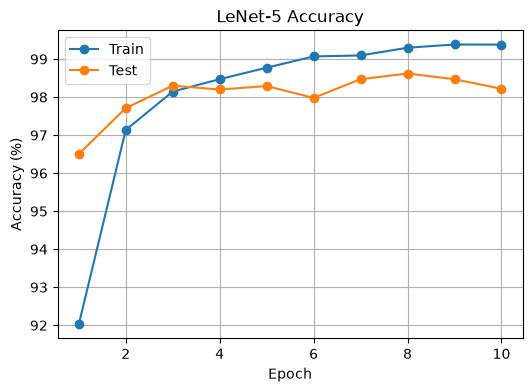

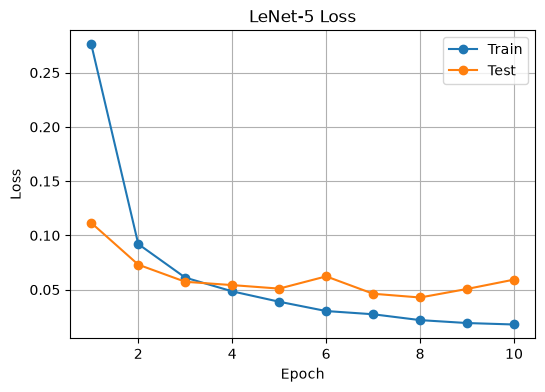

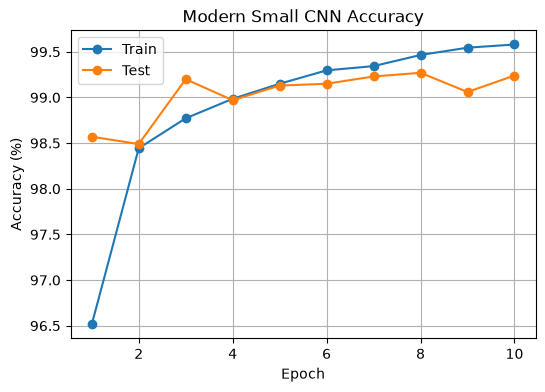

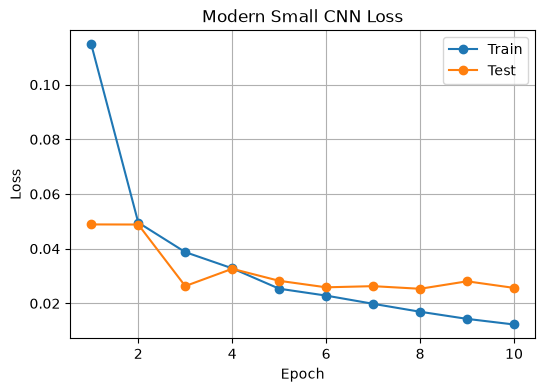

In [20]:
def plot_history(history, model_name):
    epochs = range(1, 11)

    plt.figure(figsize=(6, 4))
    plt.plot(epochs, history["train_acc"], marker="o", label="Train")
    plt.plot(epochs, history["test_acc"], marker="o", label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(model_name + " Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(epochs, history["train_loss"], marker="o", label="Train")
    plt.plot(epochs, history["test_loss"], marker="o", label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(model_name + " Loss")
    plt.legend()
    plt.grid()
    plt.show()


plot_history(lenet_history, "LeNet-5")
plot_history(small_cnn_history, "Modern Small CNN")

## 2.8 Confusion Matrices

In [21]:
def get_confusion_matrix(model, loader):
    cm = torch.zeros(10, 10, dtype=torch.int64)

    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predicted = outputs.argmax(dim=1).cpu()

            for true_label, predicted_label in zip(labels, predicted):
                cm[true_label, predicted_label] += 1

    return cm


def show_confusion_matrix(cm, title):
    plt.figure(figsize=(7, 6))
    plt.imshow(cm, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(range(10))
    plt.yticks(range(10))
    plt.colorbar()

    for i in range(10):
        for j in range(10):
            plt.text(
                j, i, int(cm[i, j]),
                ha="center",
                va="center",
                fontsize=7
            )

    plt.show()

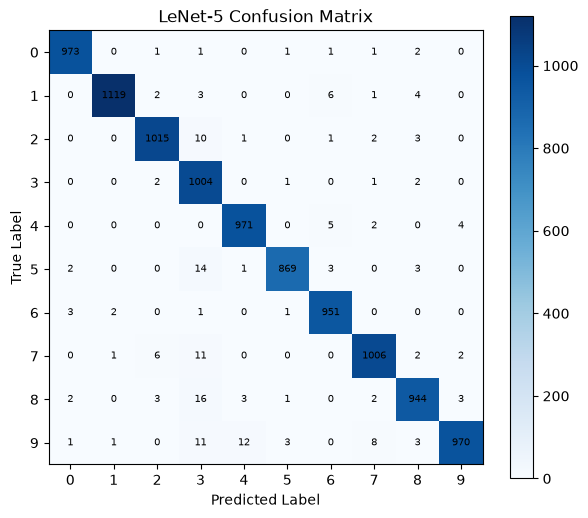

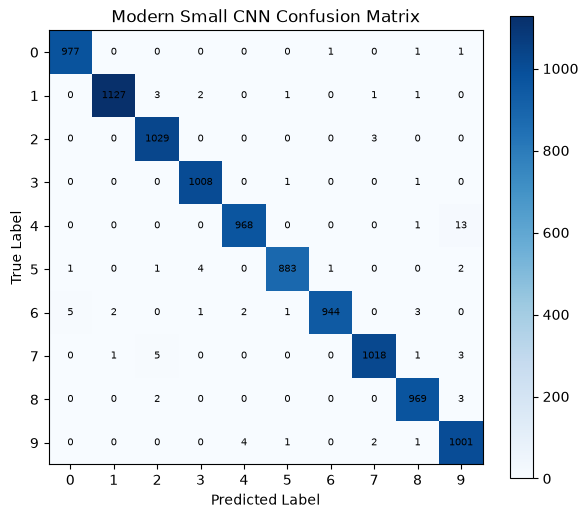

In [22]:
lenet_cm = get_confusion_matrix(lenet, mnist_testloader)
small_cnn_cm = get_confusion_matrix(small_cnn, mnist_testloader)

show_confusion_matrix(lenet_cm, "LeNet-5 Confusion Matrix")
show_confusion_matrix(small_cnn_cm, "Modern Small CNN Confusion Matrix")

## 2.9 Final Results

In [23]:
print("LeNet-5")
print(f"Final Training Accuracy: {lenet_history['train_acc'][-1]:.2f}%")
print(f"Final Test Accuracy: {lenet_history['test_acc'][-1]:.2f}%")

print()

print("Modern Small CNN")
print(f"Final Training Accuracy: {small_cnn_history['train_acc'][-1]:.2f}%")
print(f"Final Test Accuracy: {small_cnn_history['test_acc'][-1]:.2f}%")

LeNet-5
Final Training Accuracy: 99.38%
Final Test Accuracy: 98.22%

Modern Small CNN
Final Training Accuracy: 99.58%
Final Test Accuracy: 99.24%


### Comparison and Discussion

Both networks learned the MNIST digit classification task well. The modern CNN uses batch normalization, ReLU and dropout, while LeNet-5 is an older and simpler architecture. The accuracy and loss plots above show how both models changed during the 10 epochs. The confusion matrices also show which digit classes were confused with each other.

After running the notebook, mention here which model had the higher final test accuracy and any obvious confusion you can see in the matrices.

# 3. Transfer Learning with ResNet18

A ResNet18 model pretrained on ImageNet1K is used for the hymenoptera dataset. Two methods are tested: fine tuning and fixed feature extraction.

## 3.1 Download Hymenoptera Dataset

This dataset contains two classes: ants and bees. The following cell downloads the dataset only if it is not already available.

In [3]:
import urllib.request
import zipfile

data_url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
zip_path = "./data/hymenoptera_data.zip"
data_path = "./data/hymenoptera_data"

if not os.path.exists(data_path):
    os.makedirs("./data", exist_ok=True)

    print("Downloading dataset...")
    urllib.request.urlretrieve(data_url, zip_path)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("./data")

    print("Dataset ready.")
else:
    print("Dataset already exists.")

Extracting dataset...
Dataset ready.


## 3.2 Prepare Training and Validation Data

Training images use random cropping and horizontal flipping. Validation images only use resizing and center cropping. ImageNet normalization values are used because ResNet18 was pretrained on ImageNet.

In [4]:
data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

image_datasets = {
    x: datasets.ImageFolder(
        os.path.join(data_path, x),
        data_transforms[x]
    )
    for x in ["train", "val"]
}

dataloaders = {
    x: torch.utils.data.DataLoader(
        image_datasets[x],
        batch_size=4,
        shuffle=True,
        num_workers=0
    )
    for x in ["train", "val"]
}

dataset_sizes = {
    x: len(image_datasets[x])
    for x in ["train", "val"]
}

class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Training images:", dataset_sizes["train"])
print("Validation images:", dataset_sizes["val"])

Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


## 3.3 Training Function for ResNet18

In [5]:
def train_resnet(model, optimizer, scheduler, epochs=10, feature_extractor=False):
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        # Training
        model.train()
        if feature_extractor:
            model.eval()  # Keep frozen BatchNorm running statistics unchanged

        train_loss = 0.0
        train_correct = 0

        for inputs, labels in dataloaders["train"]:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()

        scheduler.step()

        train_loss /= dataset_sizes["train"]
        train_acc = 100 * train_correct / dataset_sizes["train"]

        # Validation
        model.eval()

        val_loss = 0.0
        val_correct = 0

        with torch.no_grad():
            for inputs, labels in dataloaders["val"]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()

        val_loss /= dataset_sizes["val"]
        val_acc = 100 * val_correct / dataset_sizes["val"]

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/10 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

    return history

## 3.4 Fine Tuning

For fine tuning, all ResNet18 parameters are allowed to update. The original final layer is replaced by a new layer with two outputs for ants and bees.

In [6]:
resnet_finetune = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

num_features = resnet_finetune.fc.in_features
resnet_finetune.fc = nn.Linear(num_features, 2)

resnet_finetune = resnet_finetune.to(device)

optimizer_finetune = optim.SGD(
    resnet_finetune.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_finetune = optim.lr_scheduler.StepLR(
    optimizer_finetune,
    step_size=7,
    gamma=0.1
)

finetune_history = train_resnet(
    resnet_finetune,
    optimizer_finetune,
    scheduler_finetune,
    epochs=10
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/yohanbandara/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:12<00:00, 3.63MB/s]


Epoch 1/10 | Train Loss: 0.5856 | Train Acc: 68.85% | Val Loss: 0.2092 | Val Acc: 91.50%
Epoch 2/10 | Train Loss: 0.4581 | Train Acc: 78.28% | Val Loss: 0.3626 | Val Acc: 88.24%
Epoch 3/10 | Train Loss: 0.5058 | Train Acc: 75.00% | Val Loss: 0.2776 | Val Acc: 90.85%
Epoch 4/10 | Train Loss: 0.3514 | Train Acc: 86.48% | Val Loss: 0.2961 | Val Acc: 89.54%
Epoch 5/10 | Train Loss: 0.4747 | Train Acc: 83.20% | Val Loss: 0.3942 | Val Acc: 88.89%
Epoch 6/10 | Train Loss: 0.4829 | Train Acc: 81.56% | Val Loss: 0.5280 | Val Acc: 82.35%
Epoch 7/10 | Train Loss: 0.8342 | Train Acc: 74.18% | Val Loss: 0.4287 | Val Acc: 84.97%
Epoch 8/10 | Train Loss: 0.4232 | Train Acc: 83.20% | Val Loss: 0.2926 | Val Acc: 90.85%
Epoch 9/10 | Train Loss: 0.3532 | Train Acc: 87.30% | Val Loss: 0.2824 | Val Acc: 91.50%
Epoch 10/10 | Train Loss: 0.4002 | Train Acc: 84.43% | Val Loss: 0.3196 | Val Acc: 90.20%


## 3.5 ResNet18 as a Fixed Feature Extractor

For feature extraction, the pretrained ResNet18 parameters are frozen. Only the new final fully connected layer is trained.

In [7]:
resnet_feature = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

for param in resnet_feature.parameters():
    param.requires_grad = False

num_features = resnet_feature.fc.in_features
resnet_feature.fc = nn.Linear(num_features, 2)

resnet_feature = resnet_feature.to(device)

optimizer_feature = optim.SGD(
    resnet_feature.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_feature = optim.lr_scheduler.StepLR(
    optimizer_feature,
    step_size=7,
    gamma=0.1
)

feature_history = train_resnet(
    resnet_feature,
    optimizer_feature,
    scheduler_feature,
    epochs=10,
    feature_extractor=True
)

Epoch 1/10 | Train Loss: 0.3425 | Train Acc: 84.84% | Val Loss: 0.1377 | Val Acc: 95.42%
Epoch 2/10 | Train Loss: 0.1484 | Train Acc: 93.44% | Val Loss: 0.1404 | Val Acc: 94.77%
Epoch 3/10 | Train Loss: 0.1502 | Train Acc: 93.85% | Val Loss: 0.1411 | Val Acc: 96.08%
Epoch 4/10 | Train Loss: 0.1291 | Train Acc: 95.90% | Val Loss: 0.1417 | Val Acc: 95.42%
Epoch 5/10 | Train Loss: 0.1223 | Train Acc: 93.85% | Val Loss: 0.1931 | Val Acc: 94.77%
Epoch 6/10 | Train Loss: 0.1169 | Train Acc: 95.08% | Val Loss: 0.1531 | Val Acc: 96.08%
Epoch 7/10 | Train Loss: 0.1004 | Train Acc: 96.72% | Val Loss: 0.1541 | Val Acc: 94.77%
Epoch 8/10 | Train Loss: 0.0694 | Train Acc: 97.54% | Val Loss: 0.1532 | Val Acc: 95.42%
Epoch 9/10 | Train Loss: 0.0770 | Train Acc: 98.36% | Val Loss: 0.1484 | Val Acc: 95.42%
Epoch 10/10 | Train Loss: 0.0938 | Train Acc: 97.13% | Val Loss: 0.1620 | Val Acc: 94.77%


## 3.6 Transfer Learning Results


In [8]:
print("Fine Tuning")
print(f"Final Training Accuracy: {finetune_history['train_acc'][-1]:.2f}%")
print(f"Final Validation Accuracy: {finetune_history['val_acc'][-1]:.2f}%")

print()

print("Feature Extractor")
print(f"Final Training Accuracy: {feature_history['train_acc'][-1]:.2f}%")
print(f"Final Validation Accuracy: {feature_history['val_acc'][-1]:.2f}%")


Fine Tuning
Final Training Accuracy: 84.43%
Final Validation Accuracy: 90.20%

Feature Extractor
Final Training Accuracy: 97.13%
Final Validation Accuracy: 94.77%


### Transfer Learning Discussion

Both methods start with ResNet18 weights learned from ImageNet1K. In fine tuning, all layers are updated for the ants and bees dataset. In feature extraction, the convolutional part is frozen and only the final classification layer is trained.

After running the notebook, mention which method gave the higher validation accuracy. Also mention that feature extraction normally trains faster because fewer parameters are updated.

# Final Conclusion

This assignment tested three neural network approaches. The manually trained dense network showed the forward and backward calculations directly. The MNIST experiment compared LeNet-5 with a more modern CNN. Finally, transfer learning showed how a pretrained ResNet18 can be adapted to a small two-class image dataset.

The final results from all experiments should be discussed using the actual values produced above.